# 06 · Network and route analysis

**Questions:** How is the port network structured (connectivity, hubs, route frequency)? Which origin–destination
combinations, route types and transshipment hubs are associated with elevated risk? Is route-level risk more than the
sum of its origin, destination and route-type parts?

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats as ss

from cargomind_eda import io, stats, features, plotting as P
from cargomind_eda.config import CLASSES, CLASS_COLORS

P.setup()
T = io.load_all()
net, meta = T["port_network"], T["port_metadata"]
f = features.build_shipment_features(lag_hours=1, tables=T)
f["delayed"] = (f.delay_status != "On-Time").astype(int)
f["critical"] = (f.delay_status == "Critical").astype(int)
sea = f[f.shipping_mode == "sea"].copy()
sea["hub"] = sea.transshipment_port_id.fillna("direct")

## F1. Network structure

In [2]:
print("ports:", meta.port_id.nunique(), "| routes:", len(net), "→ complete directed graph (every ordered pair has exactly one route)")
print("route_type:", net.route_type.value_counts().to_dict())
hub_use = net.groupby("transshipment_port_id").size().rename("routes_via_hub").to_frame()
hub_use["sea_shipments_via_hub"] = sea.groupby("transshipment_port_id").size()
hub_use["pct_of_sea_shipments"] = (hub_use.sea_shipments_via_hub / len(sea) * 100).round(1)
display(hub_use)
deg = pd.DataFrame({"sea_departures": sea.origin_port_id.value_counts(), "sea_arrivals": sea.destination_port_id.value_counts(),
                    "as_hub": sea.transshipment_port_id.value_counts()}).fillna(0).astype(int)
deg["total_touches"] = deg.sum(1)
deg.join(meta.set_index("port_id")[["capacity_teu_per_hour", "region"]]).sort_values("total_touches", ascending=False)

ports: 10 | routes: 90 → complete directed graph (every ordered pair has exactly one route)
route_type: {'direct': 52, 'transshipment': 38}


,routes_via_hub,sea_shipments_via_hub,pct_of_sea_shipments
transshipment_port_id,,,
AEJEA,7,592,6.3
LKCMB,9,942,10.1
MYPKG,8,1011,10.8
SGSIN,14,934,10


,sea_departures,sea_arrivals,as_hub,total_touches,capacity_teu_per_hour,region
SGSIN,1673,1533,934,4140,"4,300",Southeast Asia
CNSHA,2080,1821,0,3901,"5,600",East Asia
MYPKG,851,872,1011,2734,"1,500",Southeast Asia
AEJEA,892,959,592,2443,"1,700",Middle East
LKCMB,630,722,942,2294,900,South Asia
NLRTM,821,953,0,1774,"1,700",Europe
USLAX,742,750,0,1492,"1,100",North America
DEHAM,670,660,0,1330,960,Europe
INNSA,579,618,0,1197,650,South Asia
INMAA,409,459,0,868,180,South Asia


               count  mean  std  min  25%  50%  75%  max
route_type                                              
direct            52  29.8  4.3 16.6 28.8 30.5 32.5 35.5
transshipment     38  26.8  3.5 18.7 24.9 26.9   29 34.2
sea shipment planned duration / route planned hours: {'count': 9347.0, 'mean': 0.9995, 'std': 0.0032, 'min': 0.9829, '25%': 0.9989, '50%': 1.0, '75%': 1.0007, 'max': 1.0145}


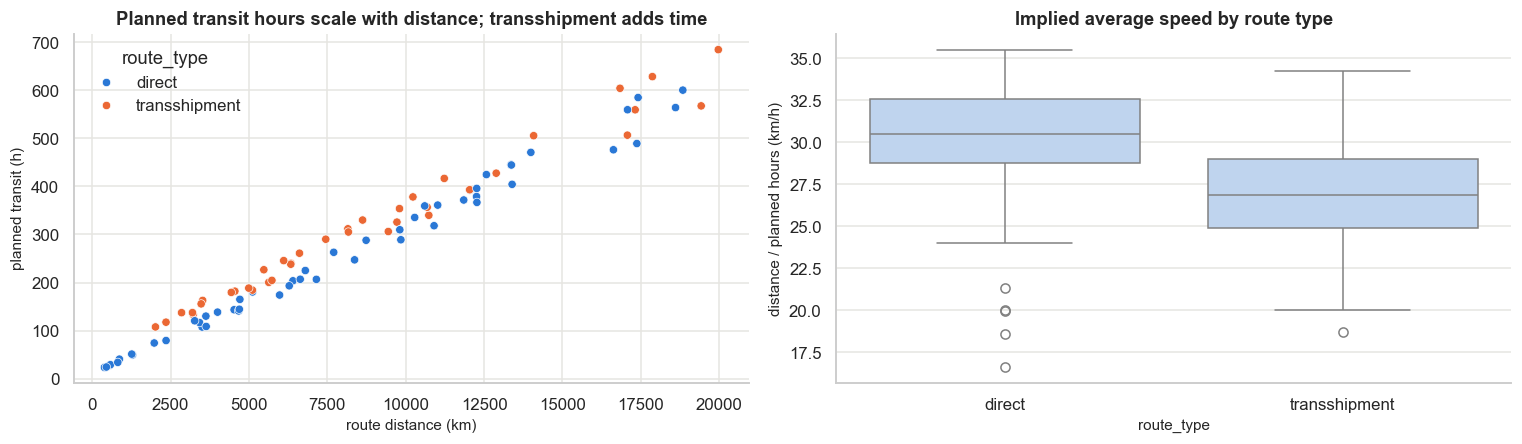

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.scatterplot(data=net, x="route_distance_km", y="planned_transit_hours", hue="route_type", palette=["#2a78d6", "#eb6834"], ax=axes[0], s=30)
axes[0].set_xlabel("route distance (km)")
axes[0].set_ylabel("planned transit (h)")
axes[0].set_title("Planned transit hours scale with distance; transshipment adds time")
net["implied_speed_kmh"] = net.route_distance_km / net.planned_transit_hours
sns.boxplot(data=net, x="route_type", y="implied_speed_kmh", ax=axes[1], color="#b7d3f6", linewidth=1)
axes[1].set_ylabel("distance / planned hours (km/h)")
axes[1].set_title("Implied average speed by route type")
P.save(fig, "06_network_distance_time")
print(net.groupby("route_type").implied_speed_kmh.describe().round(1))
print("sea shipment planned duration / route planned hours:", sea.planned_vs_route_ratio.describe().round(4).to_dict())

Sea shipments' planned durations match their route's planned transit hours to within ±1.5 % (rounding to the hour), so
`planned_duration_h` and `planned_transit_hours` are redundant for sea; they differ only for air.

## F2. Route type and transshipment hubs

In [4]:
display(stats.class_rates(sea, "route_type"))
display(stats.class_rates(sea, "hub").sort_values("pct_delayed(>12h)", ascending=False))
print(stats.chi2_vs_target(sea, "route_type"))

,n,pct_On-Time,pct_At-Risk,pct_Critical,pct_delayed(>12h),ci95_low,ci95_high
route_type,,,,,,,
direct,5868,59.3,28.7,12,40.7,39.4,42
transshipment,3479,41.4,36.4,22.3,58.6,57,60.3


,n,pct_On-Time,pct_At-Risk,pct_Critical,pct_delayed(>12h),ci95_low,ci95_high
hub,,,,,,,
SGSIN,934,38.7,36.1,25.3,61.3,58.2,64.4
LKCMB,942,39.6,38.9,21.5,60.4,57.2,63.5
AEJEA,592,42.7,36.3,20.9,57.3,53.2,61.2
MYPKG,1011,44.7,34.3,21,55.3,52.2,58.3
direct,5868,59.3,28.7,12,40.7,39.4,42


{'feature': 'route_type', 'levels': 2, 'chi2': np.float64(320.8820238721868), 'dof': 2, 'p_value': np.float64(2.0958193473226163e-70), 'cramers_v': np.float64(0.18471492472504575), 'min_expected': np.float64(549.7467636674869), 'pct_cells_expected_lt5': np.float64(0.0)}


n  pct_delayed  pct_critical
dist_band          route_type                                    
(388.399, 4524.6]  direct         1581         37.8           9.7
                   transshipment   518         59.8            18
(4524.6, 5975.4]   direct         1053         44.3          13.1
                   transshipment   681         51.4          14.1
(5975.4, 8170.5]   direct          967         34.4          10.5
                   transshipment   853         51.3          20.3
(8170.5, 12572.3]  direct         1195         45.8          13.1
                   transshipment   774         68.3            30
(12572.3, 19970.5] direct         1072         41.5          14.2
                   transshipment   653         63.2          27.7

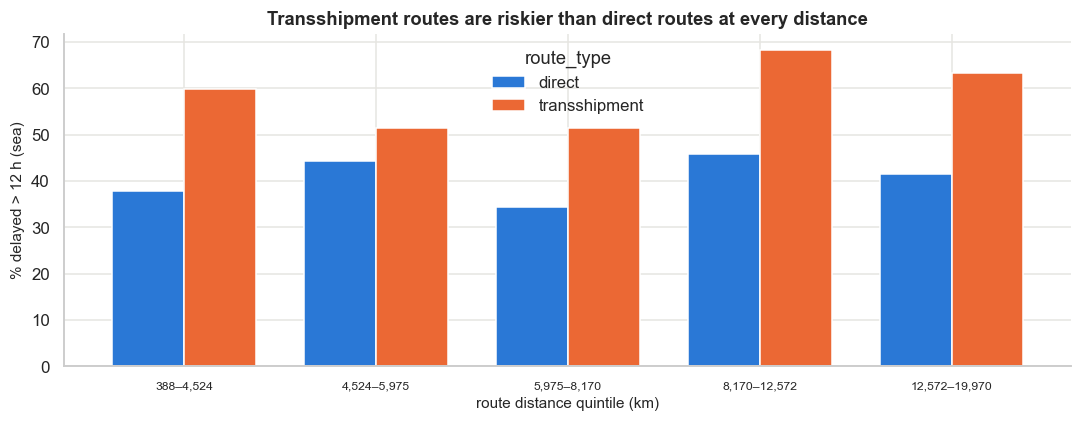

In [5]:
# Is the transshipment effect just longer distance? Compare within distance bands.
sea["dist_band"] = pd.qcut(sea.route_distance_km, 5)
tab = sea.groupby(["dist_band", "route_type"], observed=True).agg(n=("delayed", "size"), pct_delayed=("delayed", "mean"), pct_critical=("critical", "mean"))
tab[["pct_delayed", "pct_critical"]] *= 100
fig, ax = plt.subplots(figsize=(10, 4))
w = tab.pct_delayed.unstack()
w.plot.bar(ax=ax, color=["#2a78d6", "#eb6834"], width=0.75, rot=0)
ax.set_xticklabels([f"{int(i.left):,}–{int(i.right):,}" for i in w.index], fontsize=8)
ax.set_xlabel("route distance quintile (km)")
ax.set_ylabel("% delayed > 12 h (sea)")
ax.set_title("Transshipment routes are riskier than direct routes at every distance")
ax.legend(title="route_type")
P.save(fig, "06_route_type_by_distance")
tab.round(1)

## F3. Origin × destination risk map

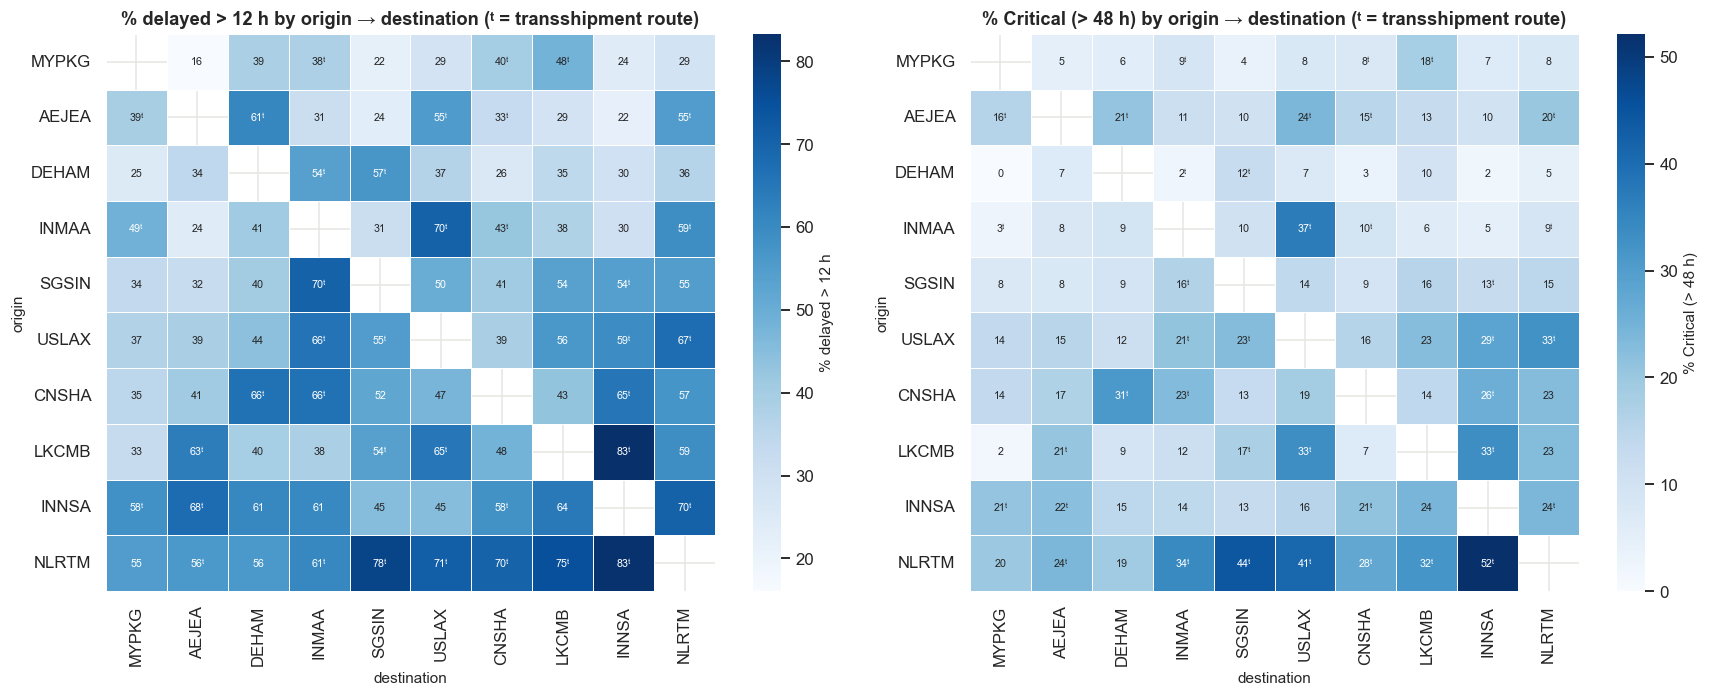

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
order = sea.groupby("origin_port_id").delayed.mean().sort_values().index
for ax, col, title in [(axes[0], "delayed", "% delayed > 12 h"), (axes[1], "critical", "% Critical (> 48 h)")]:
    m = sea.pivot_table(index="origin_port_id", columns="destination_port_id", values=col, aggfunc="mean").loc[order, order] * 100
    hubmask = net.pivot(index="origin_port_id", columns="destination_port_id", values="route_type").reindex(index=order, columns=order)
    annot = m.round(0).astype("Int64").astype(str) + np.where(hubmask == "transshipment", "ᵗ", "")
    annot = annot.where(m.notna(), "")
    sns.heatmap(m, ax=ax, cmap="Blues", annot=annot, fmt="", annot_kws={"size": 7}, cbar_kws={"label": title}, linewidths=0.5, linecolor="white")
    ax.set_title(f"{title} by origin → destination (ᵗ = transshipment route)")
    ax.set_xlabel("destination")
    ax.set_ylabel("origin")
P.save(fig, "06_od_risk_heatmap")

## F4. Is route risk additive in origin, destination and route type?
Weighted least squares on the 90 route-level delay rates (weights = shipments per route). This is a descriptive variance
decomposition, not a predictive model.

In [7]:
rt = sea.groupby("route_id").agg(n=("delayed", "size"), rate=("delayed", "mean"), crit=("critical", "mean"),
                                 origin=("origin_port_id", "first"), dest=("destination_port_id", "first"),
                                 route_type=("route_type", "first"), hub=("hub", "first"), dist=("route_distance_km", "first"))
res = {}
for name, formula in [("origin", "rate ~ C(origin)"), ("origin + dest", "rate ~ C(origin) + C(dest)"),
                      ("origin + dest + route_type", "rate ~ C(origin) + C(dest) + C(route_type)"),
                      ("origin + dest + hub", "rate ~ C(origin) + C(dest) + C(hub)")]:
    m = smf.wls(formula, data=rt, weights=rt.n).fit()
    res[name] = {"R²": m.rsquared, "adj R²": m.rsquared_adj, "params": int(m.df_model)}
rt["resid"] = smf.wls("rate ~ C(origin) + C(dest) + C(hub)", data=rt, weights=rt.n).fit().resid
# Expected residual SD from binomial sampling alone
rt["binom_se"] = np.sqrt(rt.rate * (1 - rt.rate) / rt.n)
display(pd.DataFrame(res).T.round(3))
print(f"weighted residual SD: {np.sqrt(np.average(rt.resid**2, weights=rt.n)):.3f} | mean binomial SE per route: {np.average(rt.binom_se, weights=rt.n):.3f}")

,R²,adj R²,params
origin,0.454,0.393,9
origin + dest,0.638,0.547,18
origin + dest + route_type,0.874,0.84,19
origin + dest + hub,0.91,0.881,22


weighted residual SD: 0.043 | mean binomial SE per route: 0.044


If the residual spread is of the same size as pure binomial noise, route identity adds little beyond origin, destination and
hub. That favours encoding routes through their components (low-cardinality, generalisable) over a 90-level route ID.

## F5. Route frequency and route-level risk

,epsilon_sq,cliff_Critical_vs_On-Time,spearman_rho_delay_h
feature,,,
route_departures_prev7d,0.007,-0.132,-0.084
route_distance_km,0.008,0.147,0.053
planned_transit_hours,0.012,0.181,0.079


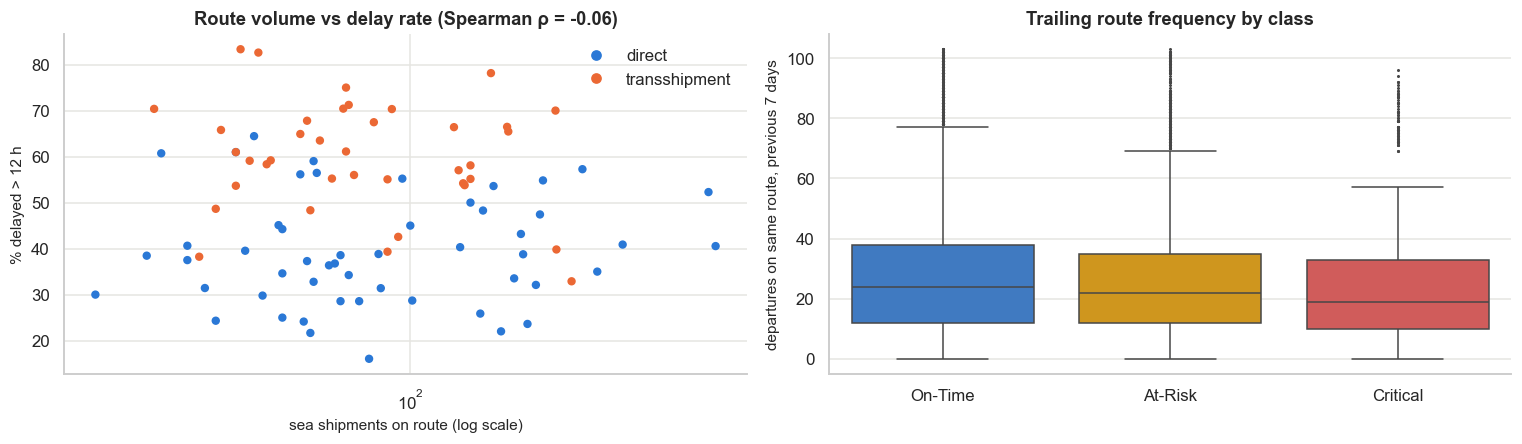

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].scatter(rt.n, rt.rate * 100, s=20, c=np.where(rt.route_type == "transshipment", "#eb6834", "#2a78d6"))
axes[0].set_xscale("log")
axes[0].set_xlabel("sea shipments on route (log scale)")
axes[0].set_ylabel("% delayed > 12 h")
axes[0].set_title(f"Route volume vs delay rate (Spearman ρ = {ss.spearmanr(rt.n, rt.rate)[0]:.2f})")
axes[0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=l) for c, l in [("#2a78d6", "direct"), ("#eb6834", "transshipment")]])
sns.boxplot(data=sea, x="delay_status", y="route_departures_prev7d", hue="delay_status", legend=False, order=CLASSES, palette=CLASS_COLORS, ax=axes[1], fliersize=1, linewidth=1)
axes[1].set_ylabel("departures on same route, previous 7 days")
axes[1].set_xlabel("")
axes[1].set_title("Trailing route frequency by class")
P.save(fig, "06_route_frequency")
display(stats.screen_numeric(sea, ["route_departures_prev7d", "route_distance_km", "planned_transit_hours"])[["epsilon_sq", "cliff_Critical_vs_On-Time", "spearman_rho_delay_h"]].round(3))

## F6. Port-specific delay patterns by role (origin, destination, hub)

,as_origin,as_destination,as_hub,n_origin
AEJEA,36.7,40,57.3,892
CNSHA,50.9,43.6,NaN,2080
DEHAM,37.5,51.8,NaN,670
INMAA,41.6,58.8,NaN,409
INNSA,58,53.1,NaN,579
LKCMB,53.3,49.2,60.4,630
MYPKG,31.3,38.6,55.3,851
NLRTM,68.3,54.1,NaN,821
SGSIN,45.2,47.4,61.3,1673
USLAX,49.5,50,NaN,742


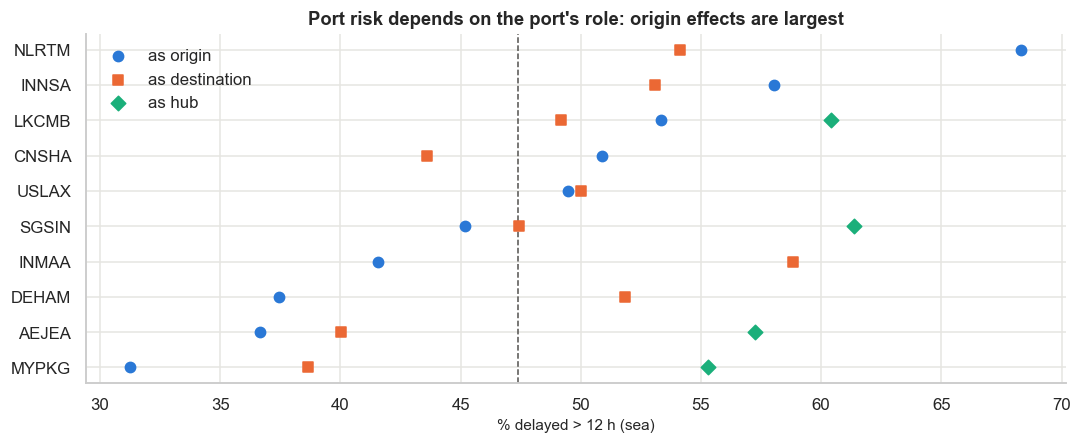

In [9]:
role = pd.DataFrame({
    "as_origin": sea.groupby("origin_port_id").delayed.mean(),
    "as_destination": sea.groupby("destination_port_id").delayed.mean(),
    "as_hub": sea.groupby("transshipment_port_id").delayed.mean(),
}) * 100
role["n_origin"] = sea.origin_port_id.value_counts()
fig, ax = plt.subplots(figsize=(10, 4.2))
r = role.sort_values("as_origin")
for col, c, mk in [("as_origin", "#2a78d6", "o"), ("as_destination", "#eb6834", "s"), ("as_hub", "#1baf7a", "D")]:
    ax.scatter(r[col], r.index, color=c, marker=mk, s=45, label=col.replace("_", " "), zorder=3)
ax.axvline(sea.delayed.mean() * 100, color="#52514e", ls="--", lw=1)
ax.set_xlabel("% delayed > 12 h (sea)")
ax.set_title("Port risk depends on the port's role: origin effects are largest")
ax.legend()
P.save(fig, "06_port_role_risk")
role.round(1)

## F7. Findings — network and routes

* The network is a **complete directed graph** of 10 ports (90 routes): connectivity itself does not vary, so "port
  connectivity" cannot be a feature in this dataset. What varies is **route type** (52 direct, 38 transshipment) and the
  **hub** (SGSIN, LKCMB, MYPKG, AEJEA).
* **Transshipment is one of the strongest structural risk factors**: 58.6 % delayed vs 40.7 % on direct routes, and 22.3 % vs
  12.0 % Critical (Cramér's V = 0.18). The gap appears in every distance quintile (+7 to +22 pp), so it is not a distance
  effect. All four hubs carry similar elevated risk (55–61 % delayed). SGSIN-hubbed routes have the highest Critical share (25 %).
* **Distance / planned transit hours** show only a weak association (ε² ≈ 0.01; δ Critical vs On-Time 0.15–0.18), mostly
  through route type.
* **Route identity is additive in its parts.** Origin + destination + hub explain R² = 0.91 of the variance in route-level
  delay rates (adj. 0.88). The weighted residual SD (0.043) equals the expected binomial sampling error (0.044), so route ID adds
  nothing measurable beyond its components. Recommendation: encode routes through origin, destination and hub (plus
  point-in-time route history), not as a 90-level ID.
* **Route frequency** shows no useful association (static volume ρ with rate shown in F5; trailing 7-day departures ε² = 0.007).
* **Port role matters.** NLRTM is the riskiest origin (68 % delayed) but only average as a destination (54 %). INMAA is a
  low-risk origin (42 %) but the riskiest destination (59 %). Hub ports are risky *as hubs* (55–61 %) whatever their origin risk
  (MYPKG is the safest origin at 31 %). Port effects must therefore be encoded per role.